# Código TP3: Clustering

In [34]:
import numpy as np
import pandas as pd
from scipy.optimize import linear_sum_assignment
from sklearn.datasets import load_iris

# https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.scale.html
from sklearn.preprocessing import scale

# https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html
from sklearn.cluster import KMeans

# https://docs.scipy.org/doc/scipy/reference/generated/scipy.cluster.hierarchy.linkage.html#scipy.cluster.hierarchy.linkage
from scipy.cluster.hierarchy import linkage, fcluster

# https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html
from sklearn.decomposition import PCA

import matplotlib.pyplot as plt

## Carga de Datasets "Crabs"

In [35]:
crabs = pd.read_csv("Crabs.csv", sep=',')
crabs = crabs.drop(columns=["rownames", "index"])
print(crabs)

crabs_numpy = crabs.to_numpy()
print(crabs_numpy)

    sp sex    FL    RW    CL    CW    BD
0    B   M   8.1   6.7  16.1  19.0   7.0
1    B   M   8.8   7.7  18.1  20.8   7.4
2    B   M   9.2   7.8  19.0  22.4   7.7
3    B   M   9.6   7.9  20.1  23.1   8.2
4    B   M   9.8   8.0  20.3  23.0   8.2
..  ..  ..   ...   ...   ...   ...   ...
195  O   F  21.4  18.0  41.2  46.2  18.7
196  O   F  21.7  17.1  41.7  47.2  19.6
197  O   F  21.9  17.2  42.6  47.4  19.5
198  O   F  22.5  17.2  43.0  48.7  19.8
199  O   F  23.1  20.2  46.2  52.5  21.1

[200 rows x 7 columns]
[['B' 'M' 8.1 ... 16.1 19.0 7.0]
 ['B' 'M' 8.8 ... 18.1 20.8 7.4]
 ['B' 'M' 9.2 ... 19.0 22.4 7.7]
 ...
 ['O' 'F' 21.9 ... 42.6 47.4 19.5]
 ['O' 'F' 22.5 ... 43.0 48.7 19.8]
 ['O' 'F' 23.1 ... 46.2 52.5 21.1]]


## Carga de Datasets "Lampone"

In [36]:
lampone = pd.read_csv("Lampone.csv", sep=',')
print(lampone)

lampone_numpy = lampone.to_numpy()
print(lampone_numpy)

    anno     m33   m34   m35   m36  m40   m41   m42    m43   m44  ...  m183  \
0   2006   32.24  0.27  0.06  0.01  0.0  0.30  0.02   2.05  0.11  ...  0.00   
1   2006   33.41  0.34  0.05  0.01  0.0  0.12  0.02  10.42  0.25  ...  0.00   
2   2006   31.93  0.32  0.05  0.01  0.0  0.09  0.02   9.32  0.24  ...  0.00   
3   2006   43.62  0.45  0.08  0.02  0.0  0.11  0.02  12.67  0.31  ...  0.00   
4   2006   47.08  0.47  0.09  0.02  0.0  0.20  0.03   3.19  0.12  ...  0.00   
5   2006   21.38  0.20  0.03  0.00  0.0  0.06  0.01  12.01  0.27  ...  0.00   
6   2006   37.20  0.38  0.06  0.01  0.0  0.07  0.02   3.45  0.14  ...  0.00   
7   2006   57.00  0.51  0.08  0.00  0.0  0.08  0.02   2.63  0.09  ...  0.00   
8   2006   13.31  0.16  0.02  0.00  0.0  0.14  0.02  11.92  0.26  ...  0.00   
9   2006  122.75  1.05  0.17  0.01  0.0  0.11  0.02   8.67  0.24  ...  0.00   
10  2006   37.70  0.37  0.05  0.00  0.0  0.09  0.02  19.00  0.39  ...  0.00   
11  2006   39.47  0.38  0.06  0.01  0.0  0.15  0.02 

## Métodos de Comparación de Resultados

In [37]:
# Comentario: para comparar dos soluciones de clustering o una de ellas
#  contra las clases originales se suele usar una tabla, como por ejemplo:

def comparar_tabla(clusters1, clusters2):

    # Suponemos a los clusters numerados desde 0
    nclusters1 = np.max(clusters1) + 1
    nclusters2 = np.max(clusters2) + 1

    conf_matrix = np.zeros((nclusters1, nclusters2), dtype=int)

    for i in range(len(clusters1)):
        conf_matrix[clusters1[i], clusters2[i]] += 1

    print(conf_matrix)
    return conf_matrix


# pero se puede optimizar el match entre los dos clusterings, para hacer
# mejor la tabla, usando:

def comparar_tabla_optim(clusters1, clusters2, verbose=True):

    # Suponemos a los clusters numerados desde 0
    nclusters1 = np.max(clusters1) + 1
    nclusters2 = np.max(clusters2) + 1

    conf_matrix = np.zeros((nclusters1, nclusters2), dtype=int)

    for i in range(len(clusters1)):
        conf_matrix[clusters1[i], clusters2[i]] += 1

    # minimum weight matching, optimize the matching between a cluster
    # in clusters1 with one or more clusters in clusters2
    _, col_ind = linear_sum_assignment(-conf_matrix)
    optimized_conf_matrix = conf_matrix[:, col_ind]

    if verbose:
        print(optimized_conf_matrix)
    return optimized_conf_matrix



## Score de Estabilidad de Soluciones de Clustering

In [38]:
# Código de ejemplo de como calcular el score de estabilidad de dos soluciones
# de clustering usando Iris

data = load_iris()
X = data.data
n = X.shape[0]

# Fijar el número de clusters
k = 5

# Crear dos muestras aleatorias del 90% de los datos
ind1 = np.random.choice(n, int(0.9 * n), replace=False)
ind2 = np.random.choice(n, int(0.9 * n), replace=False)

# Aplicar K-Means a ambas muestras
cc1 = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X[ind1]).labels_
cc2 = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X[ind2]).labels_

# Reinsertar los clusters en un vector de longitud n, con 0 en los puntos
# no seleccionados
v1 = np.zeros(n, dtype=int)
v2 = np.zeros(n, dtype=int)

# Se suman 5 a las etiquetas para permitir el truco de la raíz cuadrada
v1[ind1] = cc1 + 5
v2[ind2] = cc2 + 5

# Crear la matriz de similitud: 1 si están en el mismo cluster,
# -1 si están en distinto, 0 si alguno falta
def compute_similarity_matrix(v):
    a = np.sqrt(np.outer(v, v))
    m = np.divide(a, -a, out=np.zeros_like(a), where=a != 0) + 2 * (a == np.round(a))
    return m

def compute_similarity_matrix_fix(v):
    n = v.shape[0]
    is_valid = v > 0
    valid_mask = np.logical_and.outer(is_valid, is_valid)
    eq_mask = np.equal.outer(v, v)
    m = np.zeros((n,n), dtype=int)
    m[valid_mask & eq_mask] = 1
    m[valid_mask & ~eq_mask] = -1
    return m

m1 = compute_similarity_matrix_fix(v1)
m2 = compute_similarity_matrix_fix(v2)

# Calcular el score de estabilidad
validos = np.sum((v1 * v2) > 0)
if validos > 1:
    score = np.sum((m1 * m2)[np.triu_indices(n, k=1)] > 0) / (validos * (validos - 1) / 2)
else:
    score = 0  # Evita división por cero

print(score)

0.9784582034954613


# Ejercicio 1

## Apartado a)

varianza explicada:
  PC1: 0.9659
  PC2: 0.0236
  PC3: 0.0081
  PC4: 0.0020
  PC5: 0.0003
cargas:
[[ 0.45  0.43  0.45  0.45  0.45]
 [-0.18  0.89 -0.25 -0.13 -0.3 ]
 [-0.49 -0.06  0.33  0.66 -0.45]
 [ 0.71 -0.07  0.01  0.05 -0.7 ]
 [-0.11  0.06  0.79 -0.58 -0.15]]


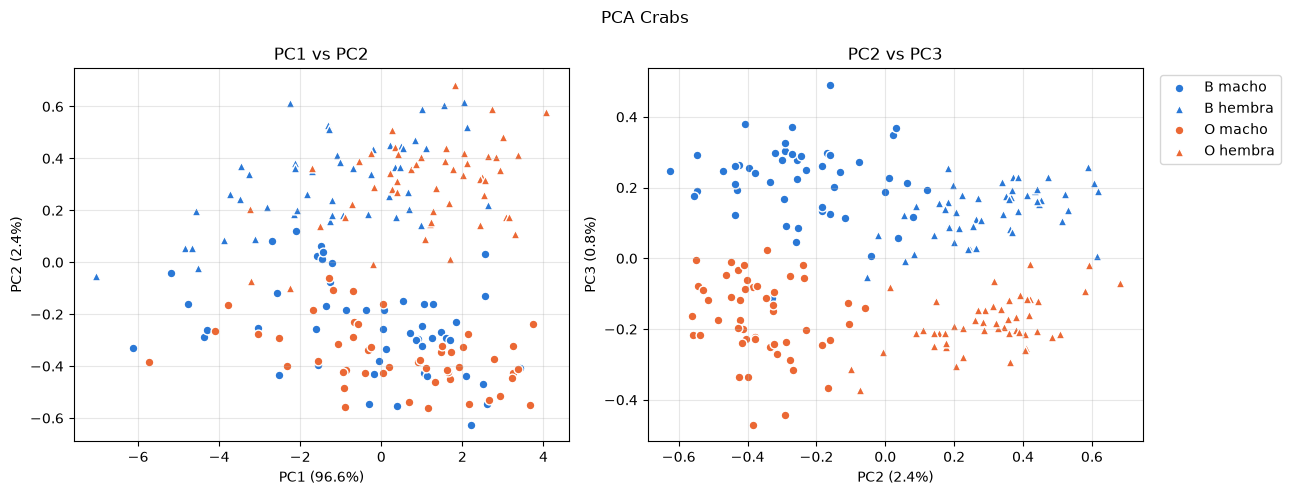

In [39]:
# PCA dataset crabs:
# Se hace una trasnformacion logaritmica, se escala y despues se aplica decomposition.PCA
X_log = np.log(crabs_numpy[:, 2:].astype(float))
X_log_esc = scale(X_log)

pca_log2 = PCA()
X_log_esc_pca = pca_log2.fit_transform(X_log_esc)
var_log2 = pca_log2.explained_variance_ratio_
print("varianza explicada:")
for i in range(len(var_log2)):
    print("  PC%d: %.4f" % (i + 1, var_log2[i]))
print("cargas:")
print(np.round(pca_log2.components_, 2))

grupos = [("B", "M", "#2a78d6", "o", "B macho"),
          ("B", "F", "#2a78d6", "^", "B hembra"),
          ("O", "M", "#eb6834", "o", "O macho"),
          ("O", "F", "#eb6834", "^", "O hembra")]

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for sp, sex, color, marker, nombre in grupos:
    idx = (crabs["sp"] == sp) & (crabs["sex"] == sex)
    ax[0].scatter(X_log_esc_pca[idx, 0], X_log_esc_pca[idx, 1], c=color, marker=marker, s=40, edgecolors="white", label=nombre)
    ax[1].scatter(X_log_esc_pca[idx, 1], X_log_esc_pca[idx, 2], c=color, marker=marker, s=40, edgecolors="white", label=nombre)

ax[0].set_xlabel("PC1 (%.1f%%)" % (var_log2[0] * 100))
ax[0].set_ylabel("PC2 (%.1f%%)" % (var_log2[1] * 100))
ax[0].set_title("PC1 vs PC2")
ax[0].grid(alpha=0.3)

ax[1].set_xlabel("PC2 (%.1f%%)" % (var_log2[1] * 100))
ax[1].set_ylabel("PC3 (%.1f%%)" % (var_log2[2] * 100))
ax[1].set_title("PC2 vs PC3")
ax[1].grid(alpha=0.3)
ax[1].legend(loc="upper left", bbox_to_anchor=(1.02, 1))

plt.suptitle("PCA Crabs")
plt.tight_layout()
plt.show()

Aplicando PCA sobre el dataset de Crabs podemos ver que la primer componente contiene la mayor parte del a varianza de los datos. Pero al ver la carga de la PC1, vemos que está compuesta casi por partes iguales por todas las variables originales. Esto se debe a que las variables son las medidas de las distintas partes del cangrejo, y todas estas medidas varían según su tamaño. Por lo que la PC1 con mayor varianza probablemente representa el tamaño del cangrejo que se midió, lo que no ayuda a definir el sexo o la especie.

Por esto se grafica la segunda y tercer componente principal, en donde se ve una clara division de las clases. Aún si no se tuviera información sobre las clases, es facil ver que existen 4 grupos distintos de datos en dicho gráfico, por lo que sería lógico aplicar técnicas de clustering para encontrar patrones en los datos.

In [43]:
# clases reales: especie + sexo (BM, BF, OM, OF -> 0..3)
clases = pd.factorize(crabs["sp"] + crabs["sex"])[0]

# pruebo con todas las componentes y solo con PC2 y PC3
for nombre, datos in [("todas las PC", X_log_esc_pca), ("PC2 y PC3", X_log_esc_pca[:, 1:3])]:
    km = KMeans(n_clusters=4, n_init=10, random_state=0).fit(datos).labels_
    jer = fcluster(linkage(datos, method="complete"), 4, criterion="maxclust") - 1

    print("-----", nombre, "-----")
    print("kmeans:")
    t = comparar_tabla_optim(clases, km)
    print("acierto:", np.trace(t) / len(clases))
    print("jerarquico:")
    t = comparar_tabla_optim(clases, jer)
    print("acierto:", np.trace(t) / len(clases))

----- todas las PC -----
kmeans:
[[20  6 14 10]
 [18 11 17  4]
 [13  4 15 18]
 [18  2  6 24]]
acierto: 0.35
jerarquico:
[[25  7 13  5]
 [21 12 16  1]
 [22  4 15  9]
 [27  2  6 15]]
acierto: 0.335
----- PC2 y PC3 -----
kmeans:
[[45  4  1  0]
 [ 1 48  1  0]
 [ 0  0 50  0]
 [ 0  2  2 46]]
acierto: 0.945
jerarquico:
[[39  0  4  7]
 [ 0 14  0 36]
 [ 0  0 50  0]
 [ 0  3  3 44]]
acierto: 0.735


Puede verse que aplicando clústering sobre todas las componentes principales, tanto k-means como jerárquico tuvieron una baja tasa de éxito al agrupar los cangrejos de la misma clase en los mismos clústers. Como se vió en la imágen del PCA, los datos de los cangrejos de la misma especie y mismo sexo no estan lo suficientemente cerca en el espacio como para que las técnicas de clustering los agrupen de forma correcta.

En cambio, al aplicar clústering sobre PC2 y PC3, se logra un acierto de entre un 73% y un 95%. Esto esta lo previsto al analizar el gráfico de la proyección de los datos sobre estos dos componentes. Con esto puede verse la importancia del análisis de los datos al aplicar técnicas de clústering, y también se ve que la componente con mayor varianza no necesariamente es la mejor para determinar la clase de los datos,

Como método de evaluación de similitud se usó Complete Linkage en el método jerárquico, el cuál busca obtener grupos compactos de puntos. Con respecto a la performance entre kmeans y jerárquico, se ve una ventaja de kmeans sobre jerárquico en el caso de PC2 y PC3. Esto puede deberse a que los métodos jerárquicos son greedy e irreversibles. Una vez que se unen dos grupos, estos no pueden separarse. Es por esto que si uno de esos grupos se forma en la frontera, pueden tomar puntos de ambas clases, y arrastrar ese error hasta el final del proceso de clústering.



## Apartado b)

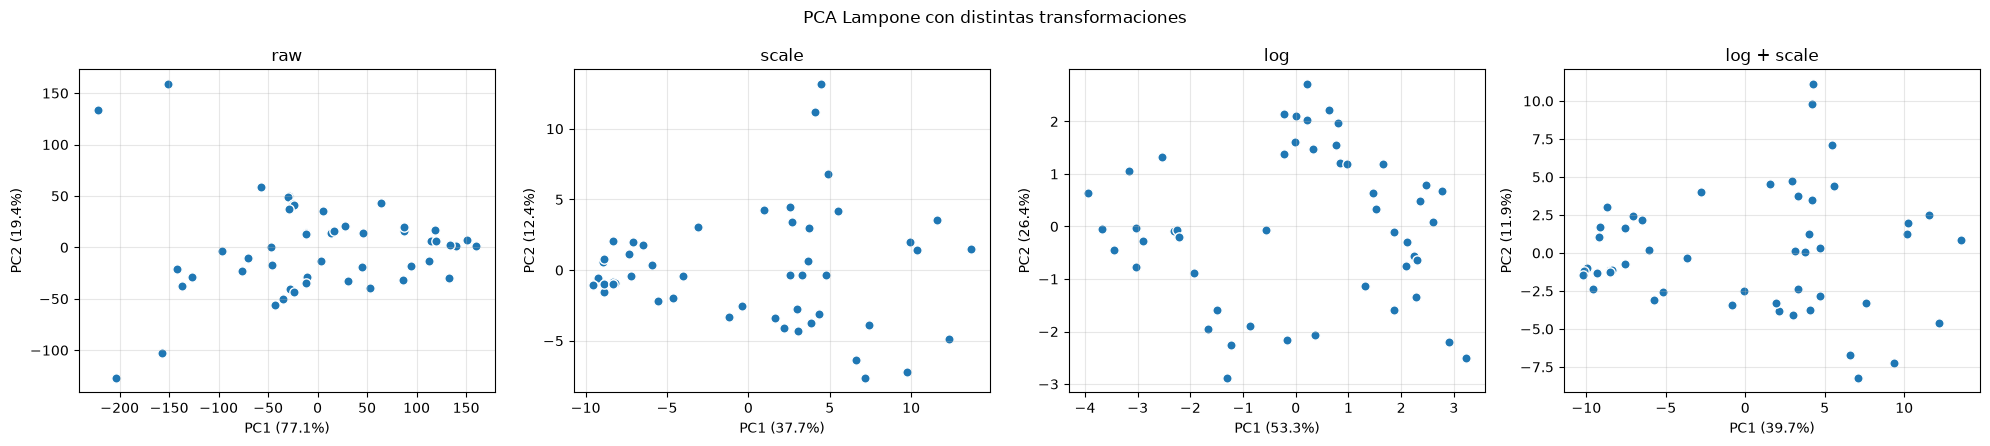

In [7]:
# PCA dataset lampone:
# columna 0: año, columna 142: especie
X_lamp = lampone_numpy[:, 1:142].astype(float)

año = pd.factorize(lampone["anno"])[0]
especie = pd.factorize(lampone["N_tipo"])[0]

escalas = {"raw": X_lamp,
           "scale": scale(X_lamp),
           "log": np.log1p(X_lamp),
           "log + scale": scale(np.log1p(X_lamp))}

fig, ax = plt.subplots(1, 4, figsize=(20, 4.5))
for i, (nombre, datos) in enumerate(escalas.items()):
    pca_lamp = PCA()
    X_lamp_pca = pca_lamp.fit_transform(datos)
    var_lamp = pca_lamp.explained_variance_ratio_
    ax[i].scatter(X_lamp_pca[:, 0], X_lamp_pca[:, 1], s=45, edgecolors="white")
    ax[i].set_title(nombre)
    ax[i].set_xlabel("PC1 (%.1f%%)" % (var_lamp[0] * 100))
    ax[i].set_ylabel("PC2 (%.1f%%)" % (var_lamp[1] * 100))
    ax[i].grid(alpha=0.3)
plt.suptitle("PCA Lampone con distintas transformaciones")
plt.tight_layout()
plt.show()

In [55]:
# clustering con 2 grupos, comparo contra el año y contra la especie
def acierto(clases, clusters):
    t = comparar_tabla_optim(clases, clusters, verbose=False)
    return np.trace(t) / len(clases)

resultados = []
for nombre, datos in escalas.items():
    km = KMeans(n_clusters=2, n_init=10, random_state=0).fit(datos).labels_
    jer = fcluster(linkage(datos, method="ward"), 2, criterion="maxclust") - 1
    resultados.append([nombre, acierto(año, km), acierto(especie, km), acierto(año, jer), acierto(especie, jer)])

print(pd.DataFrame(resultados, columns=["escala", "kmeans año", "kmeans especie", "jerárquico año", "jerárquico especie"]).round(2))

        escala  kmeans año  kmeans especie  jerárquico año  jerárquico especie
0          raw        0.92            0.57            0.94                0.59
1        scale        0.98            0.55            1.00                0.53
2          log        1.00            0.53            0.98                0.55
3  log + scale        0.98            0.55            1.00                0.53


In [57]:
# el año domina, asi que pruebo separar la especie dentro de cada año (con log)
for a in [0, 1]:
    datos = np.log1p(X_lamp[año == a])
    km = KMeans(n_clusters=2, n_init=10, random_state=0).fit(datos).labels_
    jer = fcluster(linkage(datos, method="ward"), 2, criterion="maxclust") - 1
    print("año", lampone["anno"][año == a].iloc[0])
    print("  kmeans:", acierto(especie[año == a], km))
    print("  jerarquico (ward):  ", acierto(especie[año == a], jer))

año 2006
  kmeans: 0.631578947368421
  jerarquico (ward):   0.6842105263157895
año 2007
  kmeans: 0.8
  jerarquico (ward):   0.8


Aplicando PCA sobre el dataset de Lampone con las distintas transformaciones, puede verse que en los datos originales no hay una estructura clara. Esto se debe a que unas pocas variables con valores muy grandes dominan la varianza. En cambio, al escalar o aplicar el logaritmo todas las variables pasan a tener un peso parecido, y en el escalado con log por ejemplo, se ve una separación de 4 grupos que podría ser lo que se busca.

A diferencia del ejercicio anterior, graficamos los puntos sin discriminar su clase, con el objetivo de aplicar las técnicas de clustering sin conocer previamente la clase que buscamos encontrar, y analizando si el agrupamiento surge de forma natural entre los elementos de dichas clases.

Al aplicar clústering con 2 grupos y comparar contra las clases originales, puede verse que esos dos grupos corresponden al año de la medición. Tanto k-means como jerárquico recuperan el año con un acierto de entre un 92% y un 94% sobre los datos originales, y de entre un 98% y un 100% al escalar o aplicar el logaritmo. Con la especie pasa lo contrario: el acierto está entre un 53% y un 59%, que es prácticamente lo mismo que se obtendría asignando al azar. Esto puede deberse a que la diferencia entre las mediciones de un año y otro es mucho más grande que la diferencia entre especies, por lo que los métodos de clústering agrupan por año cuando se buscan solo 2 clusters.

Por esto se probó separar los datos por año y aplicar clústering dentro de cada uno para buscar la especie. De esta forma el resultado mejora: en 2007 se logra un acierto del 80% con ambos métodos, y en 2006 de entre un 63% y un 68%. Con esto puede verse que con técnicas de clústering se puede encontrar el año de la medición, pero la especie queda opacada por el efecto del año.

Se destaca que no se notó una diferencia significativa entre los resultados de usar k-means y los de usar un clustering jerárquico usando ward como criterio de similitud, que es lo que se esperaba, ya que el método jerárquico con dicho criterio tiene a converger a la solución de k-means para la misma cantidad de clusters.

Lo que genera un impacto más significativo sobre los resultados obtenidos es la forma de proyeción y escalado de los datos que se usan para buscar los clusters.

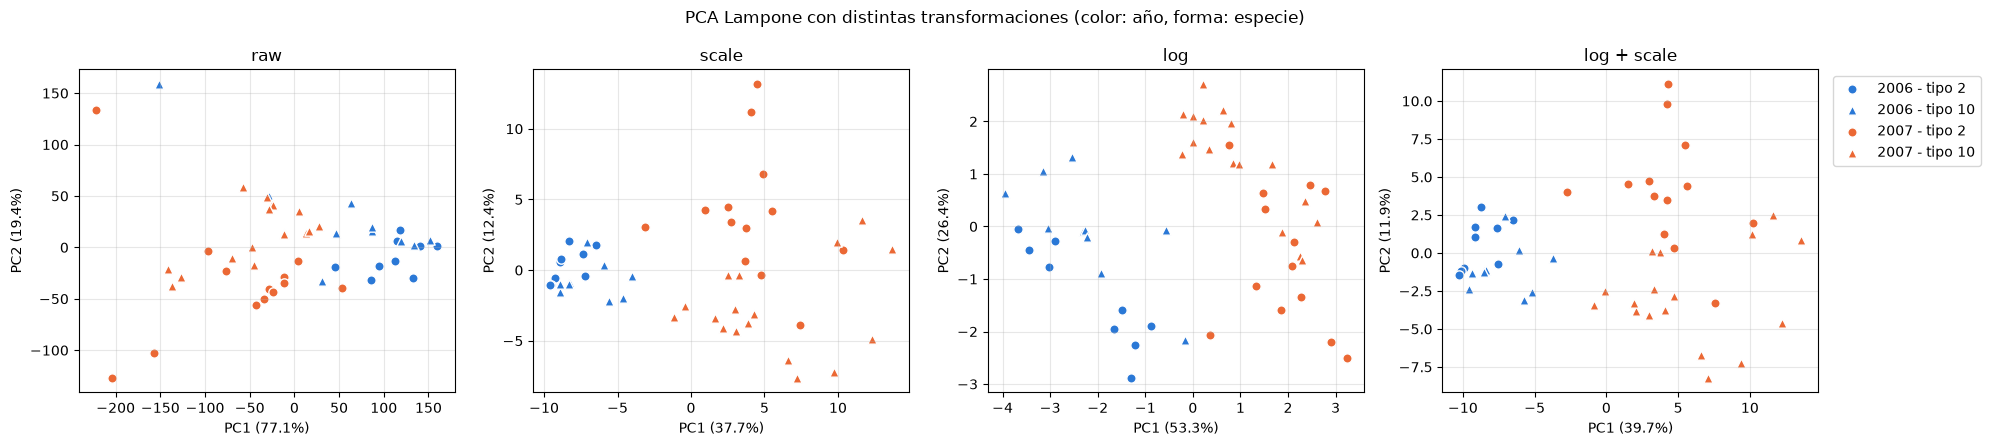

In [12]:
# PCA de cada escala mostrando las clases (color: año, forma: especie)
años = lampone["anno"].unique()
especies = lampone["N_tipo"].unique()
grupos = [(0, 0, "#2a78d6", "o"),
          (0, 1, "#2a78d6", "^"),
          (1, 0, "#eb6834", "o"),
          (1, 1, "#eb6834", "^")]

fig, ax = plt.subplots(1, 4, figsize=(20, 4.5))
for i, (nombre, datos) in enumerate(escalas.items()):
    pca_lamp = PCA()
    X_lamp_pca = pca_lamp.fit_transform(datos)
    var_lamp = pca_lamp.explained_variance_ratio_
    for a, e, color, marker in grupos:
        idx = (año == a) & (especie == e)
        ax[i].scatter(X_lamp_pca[idx, 0], X_lamp_pca[idx, 1], c=color, marker=marker, s=45, edgecolors="white",
                      label="%s - tipo %s" % (años[a], especies[e]))
    ax[i].set_title(nombre)
    ax[i].set_xlabel("PC1 (%.1f%%)" % (var_lamp[0] * 100))
    ax[i].set_ylabel("PC2 (%.1f%%)" % (var_lamp[1] * 100))
    ax[i].grid(alpha=0.3)
ax[3].legend(loc="upper left", bbox_to_anchor=(1.02, 1))
plt.suptitle("PCA Lampone con distintas transformaciones (color: año, forma: especie)")
plt.tight_layout()
plt.show()

Se grafica el PCA con las distintas trasnformaciones, esta vez diferenciando las distintas clases, y puede verse que los resultados del clústering es lógico, PC1 diferencia de forma clara el año de cada punto, pero la especie del arándano no se encuentra muy agrupáda espacialmente en la proyección, por lo que resulta complejo para el método de clústering agruparla.

# Ejercicio 2

## Apartado a)

In [ ]:
# clustering k-means, retorna las etiquetas numeradas desde 0
def kmeans_labels(X, k):
    return KMeans(n_clusters=k, n_init=10).fit(X).labels_


# clustering jerárquico, retorna las etiquetas numeradas desde 0
def ward_labels(X, k):
    return fcluster(linkage(X, method="complete"), k, criterion="maxclust") - 1


# Gap Statistic: compara el log de la dispersión de los datos con el de B
# datasets uniformes en el rango de cada componente principal.
# Retorna el k elegido, el gap y el desvío s para cada k (el índice 0 es k=1)
def gap_statistic(X, k_max = 10, B = 20):
    # gereno datasets de referencia uniformes en el rango de cada componente principal
    X = PCA().fit_transform(X)
    X_ref = [np.random.uniform(X.min(axis=0), X.max(axis=0), size=X.shape) for _ in range(B)]

    gap = np.zeros(k_max)
    s = np.zeros(k_max)
    for k in range(1, k_max + 1):
        # la inercia de k-means es la dispersión W_k: suma de las distancias
        # al cuadrado de cada punto al centro de su cluster
        log_w = np.log(KMeans(n_clusters=k, n_init=10).fit(X).inertia_)
        log_w_ref = np.array([np.log(KMeans(n_clusters=k, n_init=10).fit(Xb).inertia_) for Xb in X_ref])
        gap[k - 1] = log_w_ref.mean() - log_w
        s[k - 1] = log_w_ref.std() * np.sqrt(1 + 1 / B)

    # elijo el menor k tal que gap(k) >= gap(k+1) - s(k+1)
    for k in range(1, k_max):
        if gap[k - 1] >= gap[k] - s[k]:
            return k, gap, s
    return k_max, gap, s

## Apartado b)

In [30]:
# Estabilidad: para cada k hace clustering sobre m pares de submuestras con
# una fracción f de los datos, y mide qué tanto coinciden las dos soluciones
# en los puntos que comparten (1 = coinciden en todo).
# Retorna una matriz de (k_max - 1, m) con los scores, la fila i es k = i + 2
def estabilidad(X, k_max = 10, m = 20, f = 0.9, method=kmeans_labels):
    n = X.shape[0]
    scores = np.zeros((k_max - 1, m))

    for k in range(2, k_max + 1):
        for i in range(m):
            ind1 = np.random.choice(n, int(f * n), replace=False)
            ind2 = np.random.choice(n, int(f * n), replace=False)

            # reinserto los clusters en un vector de longitud n, sumo 1 para
            # que el 0 quede para los puntos que no se seleccionaron
            v1 = np.zeros(n, dtype=int)
            v2 = np.zeros(n, dtype=int)
            v1[ind1] = method(X[ind1], k) + 1
            v2[ind2] = method(X[ind2], k) + 1

            m1 = compute_similarity_matrix_fix(v1)
            m2 = compute_similarity_matrix_fix(v2)

            # proporción de pares (de los que estan en las dos submuestras) en
            # los que las dos soluciones coinciden
            validos = np.sum((v1 * v2) > 0)
            scores[k - 2, i] = np.sum((m1 * m2)[np.triu_indices(n, k=1)] > 0) / (validos * (validos - 1) / 2)

    return scores

Gap Statistic: elige k=3
Estabilidad, score medio para cada k: [0.955 1.    0.97  0.909 0.944 0.94  0.948]


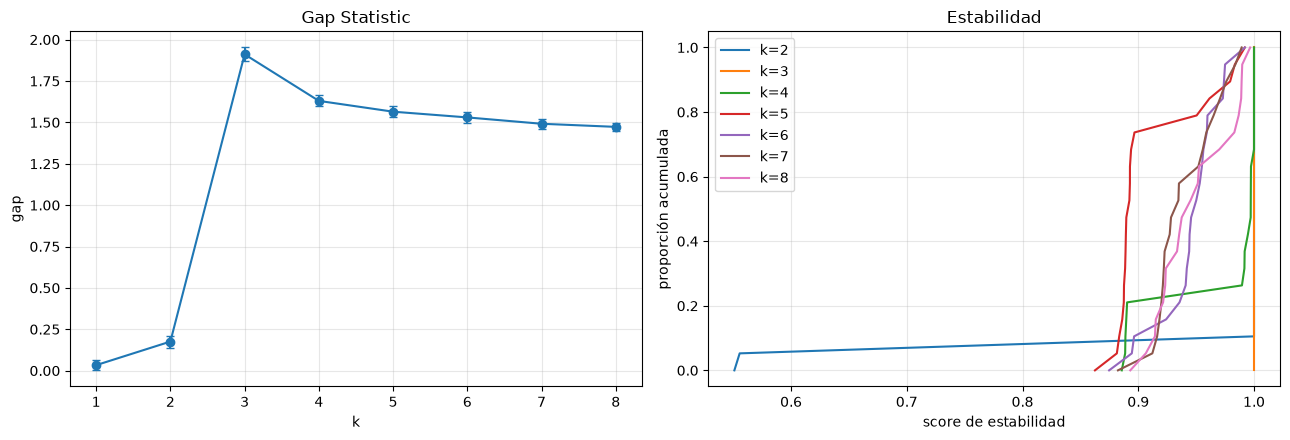

In [32]:
# pruebo los métodos con 3 gausianas bien separadas, deberían elegir k=3
medias = [[0, 0], [5, 0], [2.5, 4]]
X_prueba = np.vstack([np.random.normal(mu, 0.5, size=(100, 2)) for mu in medias])

k_opt, gap, s = gap_statistic(X_prueba, k_max=8)
print(f"Gap Statistic: elige k={k_opt}")

scores = estabilidad(X_prueba, k_max=8)
print("Estabilidad, score medio para cada k:", np.round(scores.mean(axis=1), 3))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].errorbar(range(1, 9), gap, yerr=s, marker="o", capsize=3)
ax[0].set_xlabel("k")
ax[0].set_ylabel("gap")
ax[0].set_title("Gap Statistic")
ax[0].grid(alpha=0.3)

# distribución acumulada de los scores para cada k
for k in range(2, 9):
    ax[1].plot(np.sort(scores[k - 2]), np.linspace(0, 1, scores.shape[1]), label=f"k={k}")
ax[1].set_xlabel("score de estabilidad")
ax[1].set_ylabel("proporción acumulada")
ax[1].set_title("Estabilidad")
ax[1].grid(alpha=0.3)
ax[1].legend()

plt.tight_layout()
plt.show()